In [1]:
import os

In [2]:
os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

In [3]:
processed_path = '/kaggle/input/datasets/almutalem/rehab24-6/REHAB24-6/2d_joints'
raw_path = '/kaggle/input/datasets/almutalem/raw-rehab24-6-video'

In [4]:
!ls -R {raw_path}

/kaggle/input/datasets/almutalem/raw-rehab24-6-video:
Ex1  Ex2  Ex3  Ex4  Ex5  Ex6

/kaggle/input/datasets/almutalem/raw-rehab24-6-video/Ex1:
PM_000-Camera17-30fps.mp4	      PM_024-Camera18-30fps-transposed.mp4
PM_000-Camera18-30fps-transposed.mp4  PM_032-Camera17-30fps.mp4
PM_001-Camera17-30fps.mp4	      PM_032-Camera18-30fps-transposed.mp4
PM_001-Camera18-30fps-transposed.mp4  PM_039-Camera17-30fps.mp4
PM_002-Camera17-30fps.mp4	      PM_039-Camera18-30fps-transposed.mp4
PM_002-Camera18-30fps-transposed.mp4  PM_101-Camera17-30fps.mp4
PM_012-Camera17-30fps.mp4	      PM_101-Camera18-30fps-transposed.mp4
PM_012-Camera18-30fps-transposed.mp4  PM_109-Camera17-30fps.mp4
PM_016-Camera17-30fps.mp4	      PM_109-Camera18-30fps-transposed.mp4
PM_016-Camera18-30fps-transposed.mp4  PM_114-Camera17-30fps.mp4
PM_023-Camera17-30fps.mp4	      PM_114-Camera18-30fps-transposed.mp4
PM_023-Camera18-30fps-transposed.mp4  PM_122-Camera17-30fps.mp4
PM_024-Camera17-30fps.mp4	      PM_122-Camera18-30fps-transp

In [5]:
!ls -R {processed_path}

/kaggle/input/datasets/almutalem/rehab24-6/REHAB24-6/2d_joints:
Ex1  Ex2  Ex3  Ex4  Ex5  Ex6

/kaggle/input/datasets/almutalem/rehab24-6/REHAB24-6/2d_joints/Ex1:
PM_000-c17-120fps.npy  PM_016-c18-120fps.npy  PM_101-c17-120fps.npy
PM_000-c17-30fps.npy   PM_016-c18-30fps.npy   PM_101-c17-30fps.npy
PM_000-c18-120fps.npy  PM_023-c17-120fps.npy  PM_101-c18-120fps.npy
PM_000-c18-30fps.npy   PM_023-c17-30fps.npy   PM_101-c18-30fps.npy
PM_001-c17-120fps.npy  PM_023-c18-120fps.npy  PM_109-c17-120fps.npy
PM_001-c17-30fps.npy   PM_023-c18-30fps.npy   PM_109-c17-30fps.npy
PM_001-c18-120fps.npy  PM_024-c17-120fps.npy  PM_109-c18-120fps.npy
PM_001-c18-30fps.npy   PM_024-c17-30fps.npy   PM_109-c18-30fps.npy
PM_002-c17-120fps.npy  PM_024-c18-120fps.npy  PM_114-c17-120fps.npy
PM_002-c17-30fps.npy   PM_024-c18-30fps.npy   PM_114-c17-30fps.npy
PM_002-c18-120fps.npy  PM_032-c17-120fps.npy  PM_114-c18-120fps.npy
PM_002-c18-30fps.npy   PM_032-c17-30fps.npy   PM_114-c18-30fps.npy
PM_012-c17-120fps.npy  PM_03

In [6]:
!pip install --upgrade mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 25.4 MB/s  0:00:01m0:00:0100:01
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]/3 [mediapipe]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [7]:
!wget -O pose_landmarker.task -q https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792898315.194419     162 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792898315.244969     162 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792898316.558598     161 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


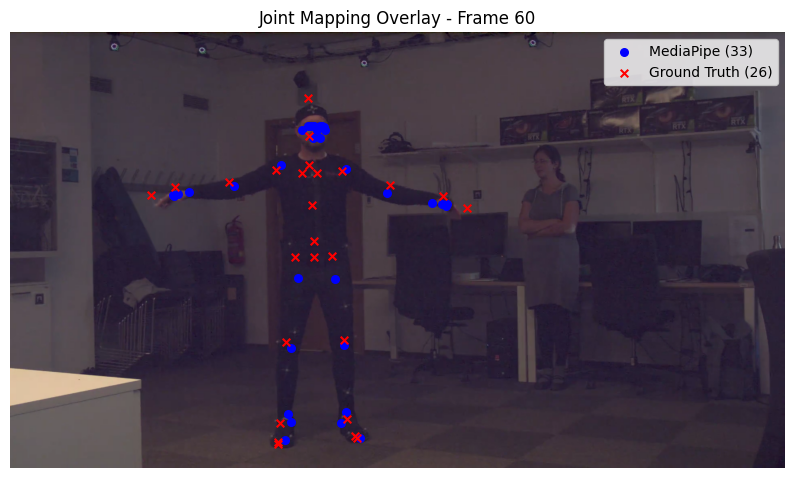

In [8]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import matplotlib.pyplot as plt

# Paths (Adjust to your exact Kaggle paths)
npy_path = f"{processed_path}/Ex1/PM_000-c17-30fps.npy"
vid_path = f"{raw_path}/Ex1/PM_000-Camera17-30fps.mp4"
model_path = "pose_landmarker.task"

def extract_and_plot_v2(video_file, npy_file, frame_idx=0):
    # Load Ground Truth 
    gt_data = np.load(npy_file) 
    gt_frame = gt_data[frame_idx] 
    
    # Initialize MediaPipe Pose Landmarker
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.PoseLandmarkerOptions(
        base_options=base_options,
        output_segmentation_masks=False,
        min_pose_detection_confidence=0.5
    )
    
    detector = vision.PoseLandmarker.create_from_options(options)
    
    # Read Video Frame
    cap = cv2.VideoCapture(video_file)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    if not ret:
        print("Frame not found")
        return
        
    h, w, _ = frame.shape
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Convert to MediaPipe Image format
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
    
    # Detect Poses
    detection_result = detector.detect(mp_image)
    
    mp_points = []
    if detection_result.pose_landmarks:
        # Get the first detected person
        landmarks = detection_result.pose_landmarks[0]
        for lm in landmarks:
            # Convert normalized coordinates to absolute pixels
            mp_points.append([lm.x * w, lm.y * h])
    mp_points = np.array(mp_points)
    
    # Plotting
    plt.figure(figsize=(10, 8))
    plt.imshow(frame_rgb)
    
    # Plot MediaPipe (33 points) in Blue
    if len(mp_points) > 0:
        plt.scatter(mp_points[:, 0], mp_points[:, 1], c='blue', s=30, label='MediaPipe (33)')
        
    # Plot Ground Truth (26 points) in Red
    plt.scatter(gt_frame[:, 0], gt_frame[:, 1], c='red', s=30, marker='x', label='Ground Truth (26)')
    
    plt.legend()
    plt.title(f"Joint Mapping Overlay - Frame {frame_idx}")
    plt.axis('off')
    plt.show()

# Run visualization for frame 60
extract_and_plot_v2(vid_path, npy_path, frame_idx=60)

W0000 00:00:1792898317.542128     180 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792898317.587417     182 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


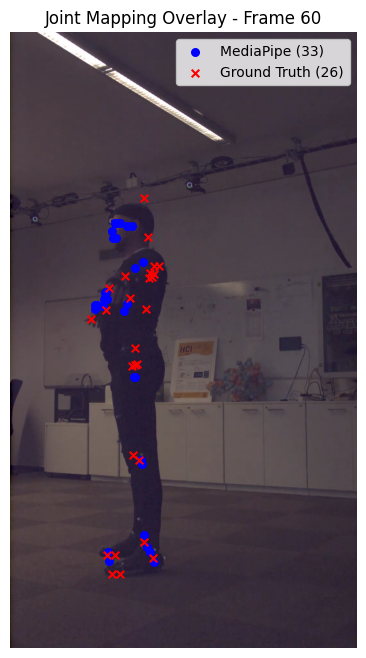

In [9]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import matplotlib.pyplot as plt

# Paths (Adjust to your exact Kaggle paths)
npy_path = f"{processed_path}/Ex1/PM_000-c18-30fps.npy"
vid_path = f"{raw_path}/Ex1/PM_000-Camera18-30fps-transposed.mp4"
model_path = "pose_landmarker.task"

def extract_and_plot_v2(video_file, npy_file, frame_idx=0):
    # Load Ground Truth 
    gt_data = np.load(npy_file) 
    gt_frame = gt_data[frame_idx] 
    
    # Initialize MediaPipe Pose Landmarker
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.PoseLandmarkerOptions(
        base_options=base_options,
        output_segmentation_masks=False,
        min_pose_detection_confidence=0.5
    )
    
    detector = vision.PoseLandmarker.create_from_options(options)
    
    # Read Video Frame
    cap = cv2.VideoCapture(video_file)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    if not ret:
        print("Frame not found")
        return
        
    h, w, _ = frame.shape
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Convert to MediaPipe Image format
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
    
    # Detect Poses
    detection_result = detector.detect(mp_image)
    
    mp_points = []
    if detection_result.pose_landmarks:
        # Get the first detected person
        landmarks = detection_result.pose_landmarks[0]
        for lm in landmarks:
            # Convert normalized coordinates to absolute pixels
            mp_points.append([lm.x * w, lm.y * h])
    mp_points = np.array(mp_points)
    
    # Plotting
    plt.figure(figsize=(10, 8))
    plt.imshow(frame_rgb)
    
    # Plot MediaPipe (33 points) in Blue
    if len(mp_points) > 0:
        plt.scatter(mp_points[:, 0], mp_points[:, 1], c='blue', s=30, label='MediaPipe (33)')
        
    # Plot Ground Truth (26 points) in Red
    plt.scatter(gt_frame[:, 0], gt_frame[:, 1], c='red', s=30, marker='x', label='Ground Truth (26)')
    
    plt.legend()
    plt.title(f"Joint Mapping Overlay - Frame {frame_idx}")
    plt.axis('off')
    plt.show()

# Run visualization for frame 60
extract_and_plot_v2(vid_path, npy_path, frame_idx=60)

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Define the MLP (Input: 33 MP joints * 2D = 66, Output: 26 GT joints * 2D = 52)
class PoseMapperMLP(nn.Module):
    def __init__(self):
        super(PoseMapperMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(66, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 52)
        )
        
    def forward(self, x):
        return self.network(x)

def train_view_model(X_train, Y_train, view_name, epochs=100, batch_size=32, lr=0.001):
    # Convert numpy arrays to PyTorch tensors
    X_tensor = torch.FloatTensor(X_train)
    Y_tensor = torch.FloatTensor(Y_train)
    
    dataset = TensorDataset(X_tensor, Y_tensor)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    model = PoseMapperMLP()
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            predictions = model(batch_x)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            
        if (epoch + 1) % 20 == 0:
            print(f"[{view_name}] Epoch {epoch+1}/{epochs} | Loss: {epoch_loss/len(loader):.4f}")
            
    # Save the trained weights
    torch.save(model.state_dict(), f"mapper_model_{view_name}.pth")
    return model

# Example Usage (Requires X_c17, Y_c17, X_c18, Y_c18 arrays shaped [N, 66] and [N, 52]):
# model_c17 = train_view_model(X_c17, Y_c17, "C17")
# model_c18 = train_view_model(X_c18, Y_c18, "C18")

In [12]:
NPY_BASE = processed_path
VID_BASE = raw_path
EXERCISES = ["Ex1", "Ex2", "Ex3", "Ex4", "Ex5", "Ex6"]

In [13]:
from tqdm.notebook import tqdm
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import os

MODEL_PATH = "pose_landmarker.task"

def extract_dataset(stride=2):
    X_c17, Y_c17 = [], []
    X_c18, Y_c18 = [], []
    
    # Initialize MediaPipe Pose Landmarker
    base_options = python.BaseOptions(model_asset_path=MODEL_PATH)
    options = vision.PoseLandmarkerOptions(
        base_options=base_options,
        output_segmentation_masks=False,
        min_pose_detection_confidence=0.5
    )
    detector = vision.PoseLandmarker.create_from_options(options)
    
    for ex in EXERCISES:
        npy_dir = os.path.join(NPY_BASE, ex)
        vid_dir = os.path.join(VID_BASE, ex)
        
        if not os.path.exists(npy_dir): continue
            
        npy_files = [f for f in os.listdir(npy_dir) if f.endswith('.npy')]
        
        for npy_name in tqdm(npy_files, desc=f"Processing {ex}"):
            parts = npy_name.replace('.npy', '').split('-')
            subject, view, fps = parts[0], parts[1], parts[2]
            
            if view == "c17":
                vid_name = f"{subject}-Camera17-{fps}.mp4"
            else:
                vid_name = f"{subject}-Camera18-{fps}-transposed.mp4"
                
            vid_path = os.path.join(vid_dir, vid_name)
            npy_path = os.path.join(npy_dir, npy_name)
            
            if not os.path.exists(vid_path):
                continue
                
            gt_data = np.load(npy_path)
            cap = cv2.VideoCapture(vid_path)
            frame_idx = 0
            
            while cap.isOpened():
                ret, frame = cap.read()
                if not ret or frame_idx >= len(gt_data):
                    break
                    
                if frame_idx % stride == 0:
                    h, w, _ = frame.shape
                    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    
                    # Tasks API requires mp.Image format
                    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
                    detection_result = detector.detect(mp_image)
                    
                    if detection_result.pose_landmarks:
                        # Extract the first detected person
                        landmarks = detection_result.pose_landmarks[0]
                        mp_pts = np.array([[lm.x * w, lm.y * h] for lm in landmarks])
                        gt_pts = gt_data[frame_idx]
                        
                        if view == "c17":
                            X_c17.append(mp_pts.flatten())
                            Y_c17.append(gt_pts.flatten())
                        else:
                            X_c18.append(mp_pts.flatten())
                            Y_c18.append(gt_pts.flatten())
                            
                frame_idx += 1
            cap.release()
            
    return np.array(X_c17), np.array(Y_c17), np.array(X_c18), np.array(Y_c18)

In [14]:
print("Extracting Data... This may take a while.")
# Using stride=2 to process every second frame. Increase to 5 or 10 if extraction takes too long.
X_17, Y_17, X_18, Y_18 = extract_dataset(stride=30)

Extracting Data... This may take a while.


W0000 00:00:1792898323.530655     194 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792898323.573859     195 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Processing Ex1:   0%|          | 0/52 [00:00<?, ?it/s]

Processing Ex2:   0%|          | 0/48 [00:00<?, ?it/s]

Processing Ex3:   0%|          | 0/40 [00:00<?, ?it/s]

Processing Ex4:   0%|          | 0/48 [00:00<?, ?it/s]

Processing Ex5:   0%|          | 0/36 [00:00<?, ?it/s]

Processing Ex6:   0%|          | 0/36 [00:00<?, ?it/s]

In [15]:
model_c17 = train_view_model(X_17, Y_17, "C17", epochs=50)
model_c18 = train_view_model(X_18, Y_18, "C18", epochs=50)
print("Training Complete. Weights saved.")

[C17] Epoch 20/50 | Loss: 861.7108
[C17] Epoch 40/50 | Loss: 644.8436
[C18] Epoch 20/50 | Loss: 1761.7274
[C18] Epoch 40/50 | Loss: 1498.9409
Training Complete. Weights saved.


W0000 00:00:1792906561.735155    1113 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792906561.892820    1113 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


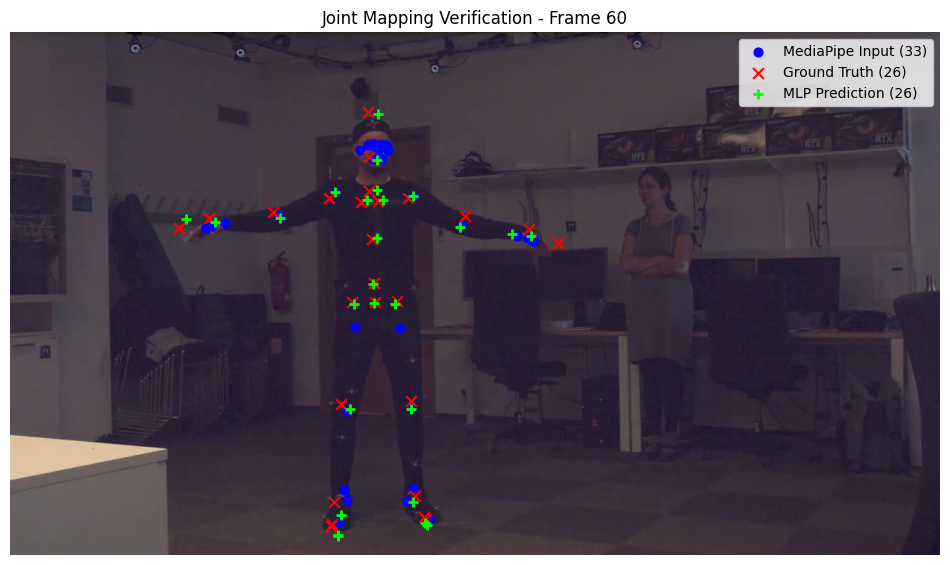

In [16]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# 1. Define your exact verify_and_plot function here
def verify_and_plot(video_file, frame_idx, mp_points, gt_points, trained_model):
    trained_model.eval()
    mp_flat = torch.FloatTensor(mp_points.flatten()).unsqueeze(0)
    
    with torch.no_grad():
        pred_flat = trained_model(mp_flat).squeeze(0).numpy()
    pred_points = pred_flat.reshape(26, 2)
    
    cap = cv2.VideoCapture(video_file)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    if not ret:
        print(f"Could not read frame {frame_idx}")
        return
        
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(12, 10))
    plt.imshow(frame_rgb)
    plt.scatter(mp_points[:, 0], mp_points[:, 1], c='blue', s=40, label='MediaPipe Input (33)')
    plt.scatter(gt_points[:, 0], gt_points[:, 1], c='red', s=60, marker='x', label='Ground Truth (26)')
    plt.scatter(pred_points[:, 0], pred_points[:, 1], c='#00FF00', s=60, marker='+', linewidths=2, label='MLP Prediction (26)')
    
    plt.title(f"Joint Mapping Verification - Frame {frame_idx}")
    plt.legend(loc='upper right')
    plt.axis('off')
    plt.show()

# 2. Wrapper function to prep the data and call verify_and_plot
def prep_and_verify(video_file, npy_file, frame_idx, trained_model, task_path="pose_landmarker.task"):
    # Get Ground Truth
    gt_data = np.load(npy_file)
    if frame_idx >= len(gt_data):
        print("Frame index out of bounds.")
        return
    gt_points = gt_data[frame_idx]

    # Get MediaPipe Landmarks
    base_options = python.BaseOptions(model_asset_path=task_path)
    options = vision.PoseLandmarkerOptions(
        base_options=base_options,
        output_segmentation_masks=False,
        min_pose_detection_confidence=0.5
    )
    detector = vision.PoseLandmarker.create_from_options(options)

    cap = cv2.VideoCapture(video_file)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    cap.release()
    
    if not ret:
        print("Could not read frame.")
        return

    h, w, _ = frame.shape
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
    detection_result = detector.detect(mp_image)
    
    if not detection_result.pose_landmarks:
        print("No pose detected in this frame.")
        return
        
    mp_points = np.array([[lm.x * w, lm.y * h] for lm in detection_result.pose_landmarks[0]])

    # Pass the prepared data into your function
    verify_and_plot(video_file, frame_idx, mp_points, gt_points, trained_model)

# --- Execution ---
vid_path = "/kaggle/input/datasets/almutalem/raw-rehab24-6-video/Ex1/PM_000-Camera17-30fps.mp4"
npy_path = "/kaggle/input/datasets/almutalem/rehab24-6/REHAB24-6/2d_joints/Ex1/PM_000-c17-30fps.npy"

prep_and_verify(vid_path, npy_path, frame_idx=60, trained_model=model_c17)

W0000 00:00:1792906696.654626    1152 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792906696.727431    1153 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


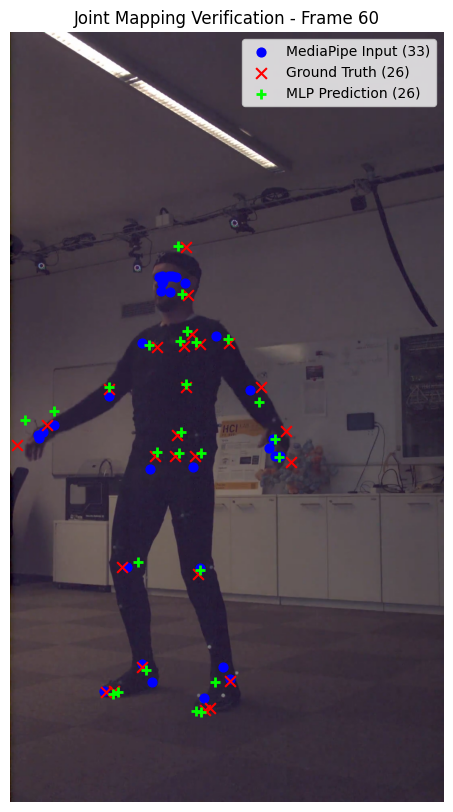

In [18]:
vid_path = "/kaggle/input/datasets/almutalem/raw-rehab24-6-video/Ex1/PM_002-Camera18-30fps-transposed.mp4"
npy_path = "/kaggle/input/datasets/almutalem/rehab24-6/REHAB24-6/2d_joints/Ex1/PM_002-c18-30fps.npy"

prep_and_verify(vid_path, npy_path, frame_idx=60, trained_model=model_c18)